In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
df = pd.read_csv("uber.csv")


In [ ]:
df = df.dropna()
df = df.drop_duplicates()

In [ ]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

In [ ]:
df = df[df["fare_amount"] > 0]

In [ ]:
df = df[df["fare_amount"] > 0]
# 2. Identify and remove outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

df = df[
    (df["fare_amount"] >= Q1 - 1.5 * IQR) &
    (df["fare_amount"] <= Q3 + 1.5 * IQR)
]

print("Dataset after removing outliers:", df.shape)


Dataset after removing outliers: (182822, 7)


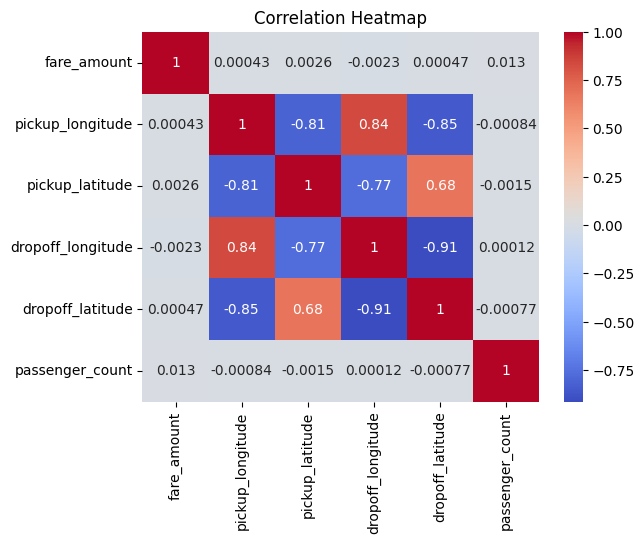

In [ ]:
# 3. Check correlation
columns = [
    "fare_amount", "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude", "passenger_count"
]

sns.heatmap(df[columns].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [11]:
# 4. Select input and output
X = df[[
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count"
]]

y = df["fare_amount"]


In [12]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [13]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred1 = lr.predict(X_test)


In [14]:
# Random Forest Regression
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
pred2 = rf.predict(X_test)

In [19]:
# 5. Evaluate and compare models
print("\nLinear Regression")
print("R2 Score:", r2_score(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))

print("\nRandom Forest Regression")
print("R2 Score:", r2_score(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))



Linear Regression
R2 Score: 6.66048690546317e-05
RMSE: 4.175141541376116

Random Forest Regression
R2 Score: 0.7051773557371865
RMSE: 2.2670760301265838
